# Antimatter-kernel Simulation Plots

After running the antimatter-kernel simulation, a file is generated at `./output/energy_analysis.csv`. You can run this notebook to analyze the results.

In [ ]:
import glob
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams.update({ "figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "axes.titlesize": 12,})

CSV_PATH = "energy_analysis.csv"  # file written by the simulation
DT = None # timestep in seconds; set it to plot against time instead of step
SAVE_FIGS = False # True: save PNGs into ./figures

In [6]:
if not os.path.exists(CSV_PATH):
    candidates = sorted(glob.glob("output/*/energy_analysis.csv"), key=os.path.getmtime)
    if not candidates:
        raise FileNotFoundError(f"Could not find {CSV_PATH!r}. Set CSV_PATH to your energy_analysis.csv.")
    CSV_PATH = candidates[-1]
print("Reading:", CSV_PATH)

df = pd.read_csv(CSV_PATH).rename(columns={
    "kinetic_energy_J": "ke",
    "trap_potential_energy_J": "pe_trap",
    "coulomb_potential_energy_J": "pe_coul",
    "total_energy_J": "total",
    "num_active_particles": "n_active",
    "fractional_drift": "drift",
})

scale = 1.0
unit = "J"
for c in ["ke", "pe_trap", "pe_coul", "total"]:
    df[c + "_s"] = df[c] * scale

x = df["step"] * DT if DT else df["step"]
xlabel = "time (s)" if DT else "step"

COMPONENTS = [("ke", "kinetic"), ("pe_trap", "trap potential"), ("pe_coul", "Coulomb potential")]

def finish(fig, name):
    fig.tight_layout()
    if SAVE_FIGS:
        os.makedirs("figures", exist_ok=True)
        fig.savefig(f"figures/{name}.png", dpi=200)
    plt.show()

df.head()

Reading: output\antimatter-kernel\energy_analysis.csv


,step,ke,pe_trap,pe_coul,total,n_active,drift,ke_s,pe_trap_s,pe_coul_s,total_s
0,0,0.000000e+00,-1.234610e-22,4.312810e-22,3.078200e-22,20,0.000000,0.000000e+00,-1.234610e-22,4.312810e-22,3.078200e-22
1,50,2.570530e-26,-1.234900e-22,4.312840e-22,3.078200e-22,20,-0.000002,2.570530e-26,-1.234900e-22,4.312840e-22,3.078200e-22
2,100,9.788180e-26,-1.235720e-22,4.312940e-22,3.078190e-22,20,-0.000003,9.788180e-26,-1.235720e-22,4.312940e-22,3.078190e-22
3,150,2.194130e-25,-1.237110e-22,4.313100e-22,3.078190e-22,20,-0.000005,2.194130e-25,-1.237110e-22,4.313100e-22,3.078190e-22
4,200,3.905920e-25,-1.239050e-22,4.313330e-22,3.078180e-22,20,-0.000006,3.905920e-25,-1.239050e-22,4.313330e-22,3.078180e-22


## 1. Data checks

In [7]:
print(f"rows: {len(df)}   steps: {df.step.min()} to {df.step.max()}")
print("missing values:", int(df.isna().sum().sum()))
print("logging interval(s) in steps:", np.unique(np.diff(df.step)))

# total should equal KE + trap PE + Coulomb PE
resid = (df.total - (df.ke + df.pe_trap + df.pe_coul)).abs() / df.total.abs()
print(f"max |total - sum of parts| / |total| = {resid.max():.2e}")

# drift column vs drift recomputed from the (rounded) total energy
recomputed = (df.total - df.total.iloc[0]) / abs(df.total.iloc[0])
print(f"max |drift(csv) - drift(recomputed)|   = {(df.drift - recomputed).abs().max():.2e}")

rows: 101   steps: 0 to 5000
missing values: 0
logging interval(s) in steps: [50]
max |total - sum of parts| / |total| = 3.90e-06
max |drift(csv) - drift(recomputed)|   = 2.70e-06


## 2. Energy components over the run

Top: the absolute energies.  
Bottom: each component's change relative to step 0, which shows how energy moves between kinetic and potential forms and how little the total changes by comparison.

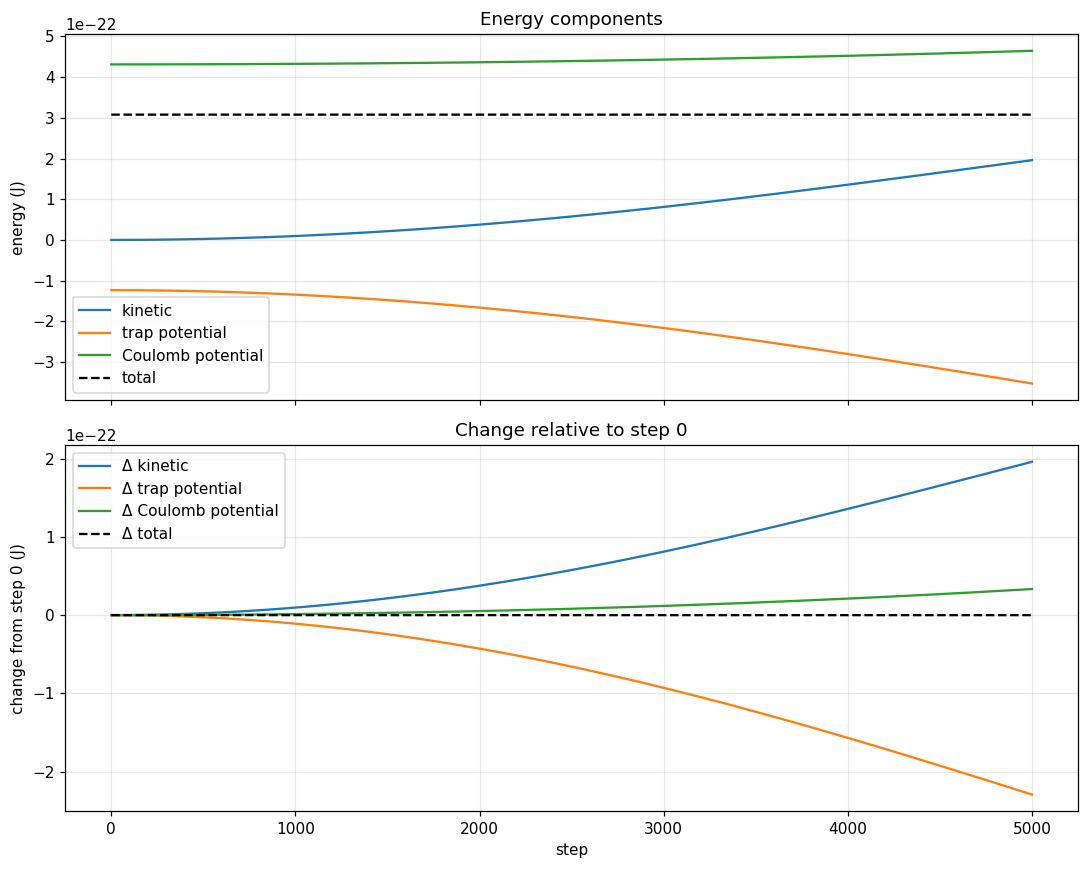

In [8]:
fig, axes = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

ax = axes[0]
for col, label in COMPONENTS:
    ax.plot(x, df[col + "_s"], label=label)
ax.plot(x, df.total_s, "k--", label="total")
ax.set(ylabel=f"energy ({unit})", title="Energy components")
ax.legend()

ax = axes[1]
for col, label in COMPONENTS:
    ax.plot(x, df[col + "_s"] - df[col + "_s"].iloc[0], label=f"Δ {label}")
ax.plot(x, df.total_s - df.total_s.iloc[0], "k--", label="Δ total")
ax.set(xlabel=xlabel, ylabel=f"change from step 0 ({unit})", title="Change relative to step 0")
ax.legend()

finish(fig, "energy_components")

## 3. Total-energy drift

The left panel shows the signed drift. The right panel shows its magnitude on log-log axes with a power-law fit, which indicates how the error grows. A slope near 1 means linear growth, a slope below 1 means the growth is slowing down, and a slope near 0.5 is what random-walk error accumulation looks like.

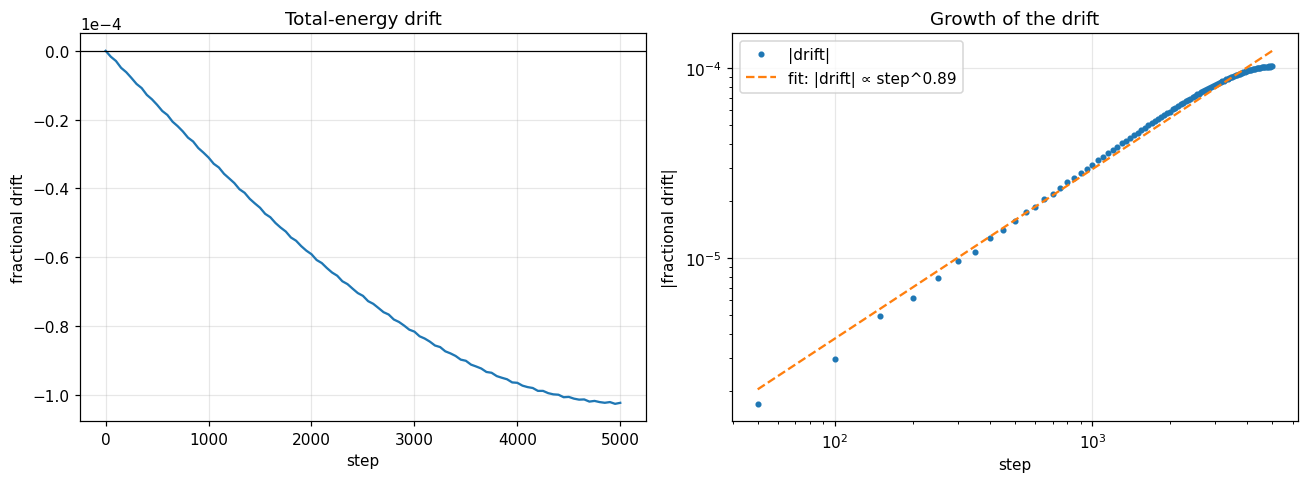

In [9]:
mask = (df.step > 0) & (df.drift != 0)
steps_m = df.step[mask].to_numpy(float)
abs_drift = df.drift[mask].abs().to_numpy()
exponent, log_prefactor = np.polyfit(np.log(steps_m), np.log(abs_drift), 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].plot(x, df.drift)
axes[0].axhline(0, color="k", lw=0.8)
axes[0].ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
axes[0].set(xlabel=xlabel, ylabel="fractional drift", title="Total-energy drift")

axes[1].loglog(steps_m, abs_drift, "o", ms=3, label="|drift|")
axes[1].loglog(steps_m, np.exp(log_prefactor) * steps_m**exponent, "--",
               label=f"fit: |drift| ∝ step^{exponent:.2f}")
axes[1].set(xlabel="step", ylabel="|fractional drift|", title="Growth of the drift")
axes[1].legend()

finish(fig, "energy_drift")

In [12]:
d = df.drift.to_numpy()
late = df.step >= df.step.max() / 2
slope_all = np.polyfit(df.step, df.drift, 1)[0]
slope_late = np.polyfit(df.step[late], df.drift[late], 1)[0]

print(f"final drift:                     {d[-1]:+.3e}")
print(f"max |drift|:                     {np.abs(d).max():.3e}")
print(f"fraction of intervals decreasing: {np.mean(np.diff(d) < 0):.2f}")
print(f"linear drift rate, whole run:    {slope_all * 1000:+.3e} per 1000 steps")
print(f"linear drift rate, second half:  {slope_late * 1000:+.3e} per 1000 steps")
print(f"power-law exponent:              {exponent:.2f}")

# Drift accumulated in five equal windows of the run
edges = np.linspace(df.step.min(), df.step.max(), 6)
rows = []
for lo, hi in zip(edges[:-1], edges[1:]):
    s = df[(df.step >= lo) & (df.step <= hi)]
    change = s.drift.iloc[-1] - s.drift.iloc[0]
    rows.append({
        "steps": f"{lo:.0f}-{hi:.0f}",
        "drift change": change,
        "per 1000 steps": change / (s.step.iloc[-1] - s.step.iloc[0]) * 1000,
    })
pd.DataFrame(rows)

final drift:                     -1.023e-04
max |drift|:                     1.026e-04
fraction of intervals decreasing: 0.95
linear drift rate, whole run:    -2.131e-05 per 1000 steps
linear drift rate, second half:  -1.253e-05 per 1000 steps
power-law exponent:              0.89


,steps,drift change,per 1000 steps
0,0-1000,-0.000031,-0.000031
1,1000-2000,-0.000028,-0.000028
2,2000-3000,-0.000022,-0.000022
3,3000-4000,-0.000015,-0.000015
4,4000-5000,-0.000006,-0.000006


## 4. Rate of energy exchange

The per-step rate of change of each component. A rate that levels off means that component is settling towards a steady state, and a rate that keeps growing means the system is still evolving.

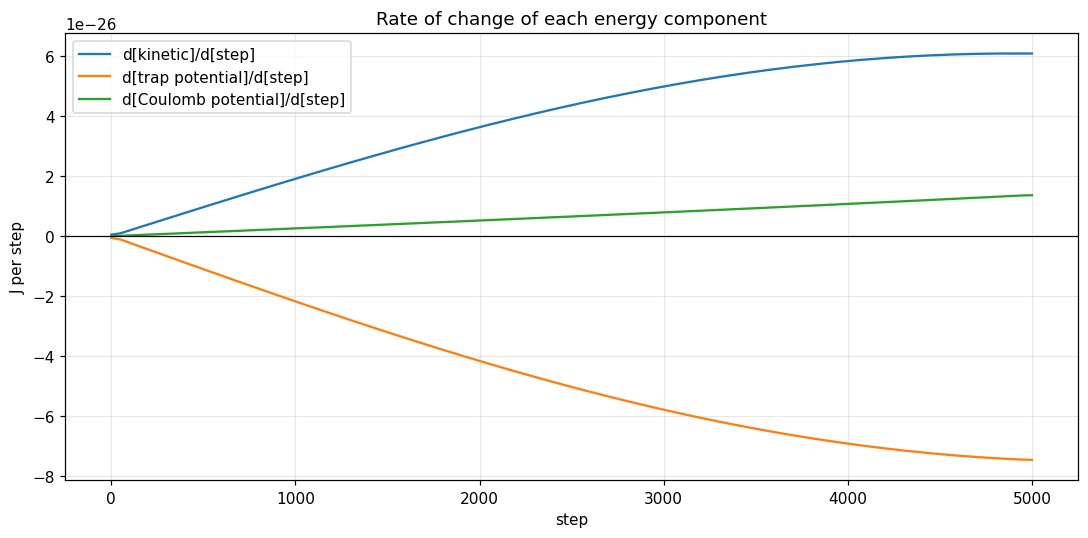

In [14]:
fig, ax = plt.subplots(figsize=(10, 5))
for col, label in COMPONENTS:
    ax.plot(x, np.gradient(df[col + "_s"], df.step), label=f"d[{label}]/d[step]")
ax.axhline(0, color="k", lw=0.8)
ax.set(xlabel=xlabel, ylabel=f"{unit} per step", title="Rate of change of each energy component")
ax.legend()
finish(fig, "energy_rates")

## 5. Particle count

Annihilation events show up as a drop in `num_active_particles`.

In [18]:
n0, n1 = int(df.n_active.iloc[0]), int(df.n_active.iloc[-1])
print(f"Active particles: {n0} at start, {n1} at end")

if df.n_active.nunique() > 1:
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.step(x, df.n_active, where="post")
    ax.set(xlabel=xlabel, ylabel="active particles", title="Active particles over time")
    finish(fig, "active_particles")
else:
    print("No particles were lost during this run.")

Active particles: 20 at start, 20 at end
No particles were lost during this run.


## 6. Summary

In [19]:
summary = pd.Series({
    "steps simulated": int(df.step.max()),
    "particles (start / end)": f"{n0} / {n1}",
    f"initial total energy ({unit})": df.total_s.iloc[0],
    f"final total energy ({unit})": df.total_s.iloc[-1],
    f"initial kinetic energy ({unit})": df.ke_s.iloc[0],
    f"final kinetic energy ({unit})": df.ke_s.iloc[-1],
    f"change in trap potential ({unit})": df.pe_trap_s.iloc[-1] - df.pe_trap_s.iloc[0],
    f"change in Coulomb potential ({unit})": df.pe_coul_s.iloc[-1] - df.pe_coul_s.iloc[0],
    "final fractional drift": d[-1],
    "max |fractional drift|": np.abs(d).max(),
    "drift power-law exponent": exponent,
    "drift rate, second half (per 1000 steps)": slope_late * 1000,
}, name="value")
summary.to_frame()

,value
steps simulated,5000
particles (start / end),20 / 20
initial total energy (J),0.0
final total energy (J),0.0
initial kinetic energy (J),0.0
final kinetic energy (J),0.0
change in trap potential (J),-0.0
change in Coulomb potential (J),0.0
final fractional drift,-0.000102
max |fractional drift|,0.000103
